# Proyecto Parcial I: Predicción del rendimiento académico con aprendizaje automático
**Universidad de Guayaquil — Carrera de Ciencia de Datos e Inteligencia Artificial**

**Paralelo:** 4-2 | **Grupo:** E | **Fecha:** 25 de noviembre de 2026

**Integrantes:**
- Granda Zambrano Cecilia Lorena
- Almeida Terry
- Campoverde María Fernanda
- Molina Sarco Juan
- Núñez Katherine

**Dataset:** Student Performance, Matemáticas (`student-mat.csv`), Cortez y Silva (2008).

**Preguntas:** (1) ¿Qué nota final obtendrá un estudiante? (2) ¿Aprobará o reprobará?

---
**Archivo independiente:** Parte2 Preprocesamiento

In [1]:
# Librerías
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge, Lasso
from sklearn.metrics import (mean_squared_error, r2_score, accuracy_score, precision_score,
                             recall_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score)
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset
import statsmodels.api as sm

SEED = 2026  # semilla del grupo (justificación en la Parte 2.5)

In [2]:
# Carga del dataset: funciona en Google Colab, en el PC, en GitHub Codespaces y en GitHub Actions
ARCHIVO = 'student-mat.csv'
rutas = [ARCHIVO, os.path.join('data', ARCHIVO)]
ruta = next((r for r in rutas if os.path.exists(r)), None)

if ruta is None:
    try:                      # solo existe en Google Colab
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(f'Copie {ARCHIVO} en la misma carpeta del notebook.')
    print(f'Seleccione el archivo {ARCHIVO}')
    subido = files.upload()
    ruta = next(iter(subido))

df = pd.read_csv(ruta, sep=None, engine='python')  # detecta separador ',' o ';'
assert df.shape[1] == 33, 'El archivo no es el student-mat.csv esperado (33 columnas).'
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [3]:
# Tipos de variables
num_cols = df.select_dtypes('number').columns.tolist()
cat_cols = [c for c in df.columns if c not in num_cols]

## Parte 2. Preprocesamiento
### 2.1 Faltantes y duplicados

In [4]:
# 2.1 Faltantes y duplicados en el dataset original
print('Faltantes originales:', df.isnull().sum().sum())
print('Filas duplicadas    :', df.duplicated().sum())

# Introducir 5 % de faltantes al azar (sobre una copia, para no alterar el EDA)
datos = df.copy()
rng = np.random.default_rng(SEED)
n_nan = int(round(0.05 * len(datos)))
for col in ['absences', 'studytime']:
    datos[col] = datos[col].astype(float)
    datos.loc[rng.choice(datos.index, size=n_nan, replace=False), col] = np.nan
print(datos[['absences', 'studytime']].isnull().sum())
print((datos[['absences', 'studytime']].isnull().mean() * 100).round(2))
print(df[['absences', 'studytime']].agg(['mean', 'median', 'skew']).round(2))

Faltantes originales: 0
Filas duplicadas    : 0
absences     20
studytime    20
dtype: int64
absences     5.06
studytime    5.06
dtype: float64
        absences  studytime
mean        5.71       2.04
median      4.00       2.00
skew        3.67       0.63


El archivo original no tiene faltantes ni duplicados. Se introdujo un 5 % (20 filas por variable) en `absences` y `studytime`.

**Imputación: mediana.** `absences` es muy asimétrica (asimetría 3.67) y la media se desplaza por los valores extremos. `studytime` es ordinal (1 a 4), y la mediana conserva un nivel con sentido. La imputación se hace **dentro del Pipeline**: la mediana se calcula solo con entrenamiento, lo que evita fuga de datos. Para las categóricas se deja la moda como protección ante datos nuevos incompletos.

### 2.2 Valores atípicos

Q1=0.0 | Q3=8.0 | IQR=8.0 | Límites=[-12.0, 20.0]
Atípicos: 14 (3.5 %) | Máximo: 75


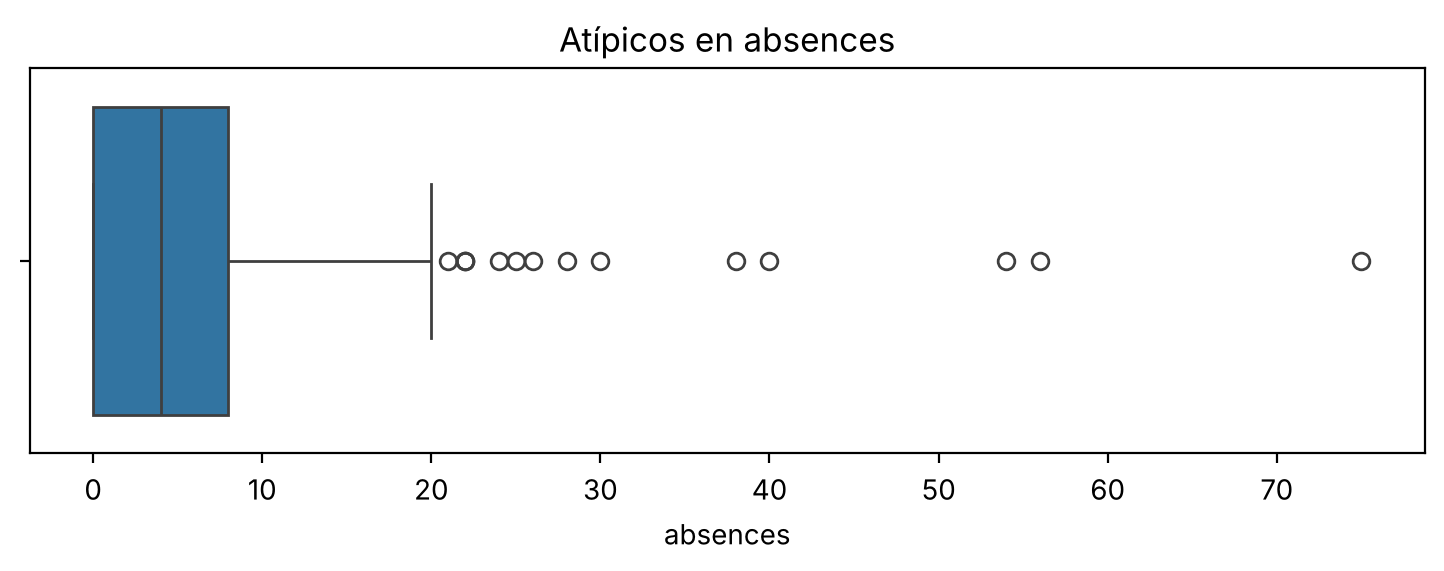

In [5]:
# 2.2 Atípicos en absences con la regla IQR
Q1, Q3 = datos['absences'].quantile([0.25, 0.75])
IQR = Q3 - Q1
lim_inf, lim_sup = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
atip = datos[(datos.absences < lim_inf) | (datos.absences > lim_sup)]
print(f'Q1={Q1} | Q3={Q3} | IQR={IQR} | Límites=[{lim_inf}, {lim_sup}]')
print(f'Atípicos: {len(atip)} ({len(atip)/len(datos)*100:.1f} %) | Máximo: {datos.absences.max():.0f}')
plt.figure(figsize=(9, 2.5)); sns.boxplot(x=datos['absences']); plt.title('Atípicos en absences'); plt.show()

**Decisión: conservarlos.** Hay 14 valores sobre el límite de 20. Son cantidades de ausencias posibles, no hay evidencia de que sean errores de registro, y las ausencias elevadas pueden ser una señal de riesgo. Eliminarlos reduciría una muestra ya pequeña. Como limitación, pueden influir en los coeficientes lineales.

### 2.3 a 2.5 Codificación, escalado, Pipeline y división
- **One-Hot Encoding:** los modelos necesitan entradas numéricas y las categorías nominales no tienen orden. `drop='first'` deja una categoría de referencia y evita columnas perfectamente colineales.
- **Estandarización:** pone las numéricas en una escala comparable. Es importante para la regularización (logística, Ridge y Lasso) y la convergencia. En la regresión lineal sin regularización no cambia las predicciones.
- **Pipeline + ColumnTransformer:** aplica los mismos pasos en entrenamiento y prueba, ajustándolos solo con entrenamiento.
- **Semilla 2026:** corresponde al año en que el grupo desarrolla el proyecto. Se usa una sola vez definida y no se prueban otras para mejorar los resultados.

In [6]:
# Variable objetivo de clasificación (Parte 4.1)
datos['aprueba'] = (datos['G3'] >= 10).astype(int)

# 2.5 División 80/20. Se usa la MISMA partición para todos los modelos.
train, test = train_test_split(datos, test_size=0.20, random_state=SEED)
print(f'Entrenamiento: {len(train)} | Prueba: {len(test)}')

Entrenamiento: 316 | Prueba: 79


In [7]:
# 2.3 y 2.4 Preprocesamiento dentro de Pipeline + ColumnTransformer
feat_A = [c for c in df.columns if c != 'G3']                 # incluye G1 y G2
feat_B = [c for c in feat_A if c not in ['G1', 'G2']]         # sin G1 ni G2

def crear_pipeline(features, modelo):
    """Imputa, escala y codifica. Todo se ajusta solo con los datos de entrenamiento."""
    nums = [c for c in features if c in num_cols]
    cats = [c for c in features if c in cat_cols]
    prep = ColumnTransformer([
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                          ('scaler', StandardScaler())]), nums),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                          # drop='first' evita la multicolinealidad perfecta entre dummies
                          ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'))]), cats)
    ], sparse_threshold=0)
    return Pipeline([('preprocessor', prep), ('model', modelo)])

y_train, y_test = train['G3'], test['G3']

In [8]:
# Comprobación: ajustar el preprocesamiento SOLO con entrenamiento y aplicarlo a prueba
for nombre, feats in [('A', feat_A), ('B', feat_B)]:
    prep = crear_pipeline(feats, LinearRegression()).named_steps['preprocessor']
    Xtr = prep.fit_transform(train[feats]); Xte = prep.transform(test[feats])
    print(f'Modelo {nombre}: train {Xtr.shape} | test {Xte.shape} | faltantes: {np.isnan(Xtr).sum() + np.isnan(Xte).sum()}')

Modelo A: train (316, 41) | test (79, 41) | faltantes: 0
Modelo B: train (316, 39) | test (79, 39) | faltantes: 0


## Referencias
Cortez, P., & Silva, A. (2008). Using data mining to predict secondary school student performance. En A. Brito & J. Teixeira (Eds.), *Proceedings of 5th Future Business Technology Conference (FUBUTEC 2008)* (pp. 5–12). EUROSIS.

> **Pendiente del grupo:** agregar en APA 7 las fuentes que realmente hayan consultado en la biblioteca de la Universidad.

## Declaración de uso de inteligencia artificial
Se utilizó Claude (Anthropic) para revisar el notebook frente a la guía, corregir y completar el código, ejecutarlo y redactar un borrador de las interpretaciones y conclusiones. El grupo debe revisar el contenido, redactar las respuestas con sus propias palabras y poder explicar cada línea en la defensa.